# 6. Explainable AI dengan SHAP

Dua hal yang ditampilkan: pengaruh fitur secara global dan penjelasan untuk satu prediksi.
Karena model terpilih adalah Random Forest, penjelas yang dipakai adalah `TreeExplainer`.

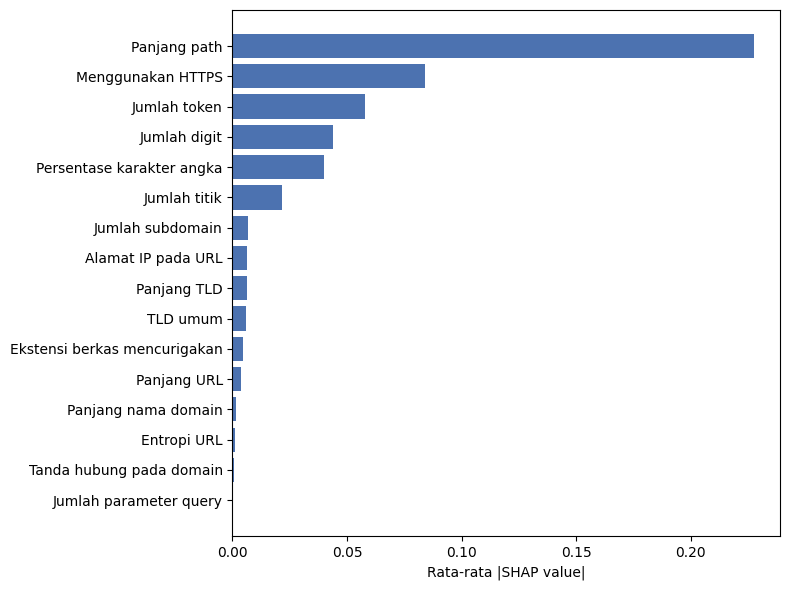

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "app").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import shap
from app.feature_extraction import FEATURE_LABELS, FEATURE_NAMES, extract_feature_dataframe

artikel = joblib.load(ROOT / "models" / "phishing_pipeline.joblib")
model = artikel["pipeline"]
uji = pd.read_csv(ROOT / "dataset" / "processed" / "data_uji.csv")
contoh = uji[FEATURE_NAMES].sample(n=200, random_state=42)

explainer = shap.TreeExplainer(model.named_steps["clf"])
nilai = explainer.shap_values(contoh)
if isinstance(nilai, list):
    nilai = nilai[1]
else:
    nilai = nilai[:, :, 1]

penting = pd.Series(abs(nilai).mean(axis=0), index=FEATURE_NAMES).sort_values()
label = [FEATURE_LABELS[name] for name in penting.index]

plt.figure(figsize=(8, 6))
plt.barh(label, penting.values, color="#4c72b0")
plt.xlabel("Rata-rata |SHAP value|")
plt.tight_layout()
plt.show()

In [2]:
url_contoh = "http://login-verify.account-update.example.com/signin"
fitur = extract_feature_dataframe([url_contoh])
prediksi = int(model.predict(fitur)[0])
probabilitas = model.predict_proba(fitur)[0][list(model.classes_).index(prediksi)]

nilai_satu = explainer.shap_values(fitur)
if isinstance(nilai_satu, list):
    arsip = nilai_satu[prediksi][0]
else:
    arsip = nilai_satu[0, :, prediksi]

tabel = pd.DataFrame({
    "fitur": [FEATURE_LABELS[name] for name in FEATURE_NAMES],
    "nilai": fitur.iloc[0].round(2).values,
    "kontribusi": arsip.round(4),
})
tabel["abs"] = tabel["kontribusi"].abs()
tabel = tabel.sort_values("abs", ascending=False).drop(columns="abs").head(5)

print("Prediksi:", artikel["label_map"][prediksi], "| keyakinan:", round(float(probabilitas), 4))
print(tabel.to_string(index=False))

Prediksi: Phishing | keyakinan: 0.978
            fitur  nilai  kontribusi
     Panjang path    7.0      0.3288
Menggunakan HTTPS    0.0      0.1306
     Jumlah token    7.0      0.0418
     Jumlah titik    3.0      0.0401
     Jumlah digit    0.0     -0.0390
